# Supervised Hebbian category learning

This local extension learns the category prior one labeled example at a time. Each example activates its supplied category and one value of each feature. The corresponding category–feature connections strengthen by the learning rate.

$$
\Delta w_{c,jv}=\eta\,s_c\,a_{jv},\qquad
P(f_j=v\mid c)=\frac{w_{c,jv}}{\sum_u w_{c,ju}}.
$$

The first equation implements co-activation learning. The second reads connection strengths as categorical probabilities. Positive initial weights provide the same pseudocounts as the original batch fitter.

At learning rate 1, one pass and matching initial weights, the learned prior matches batch counting. The experiment below checks this equivalence and shows how the prior develops as examples arrive. The training labels and feature values are supplied. The VSA codebooks stay fixed. Category labels are withheld in completion tests.

Open this notebook from this directory, then run all cells. The implementation is in `hebbian_prior.py`. The full learned-prior experiment is available in `vsa_gestalt_closure_learned_priors.ipynb`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "hebbian_prior.py").exists():
    ROOT = ROOT / "BayesContourProcessing"
if not (ROOT / "hebbian_prior.py").exists():
    raise FileNotFoundError("Open the notebook from the project directory or its parent.")
sys.path.insert(0, str(ROOT))
from closure_model import *
from hebbian_prior import SupervisedHebbianPrior
from vsa_inference import PixelVSA, posterior, mean_field

OUT = ROOT / "outputs" / "hebbian"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## Settings

The learning rate controls the strength of each observed co-activation relative to the initial pseudocounts. With this additive rule it changes the effective amount of smoothing. Training order affects intermediate beliefs, while the final additive weights depend on how many times each pair co-activated. Repeating epochs counts the same observations again. This version uses one pass.

In [2]:
SEED = 7
N_TRAIN_PER_CLASS = 250
SMOOTHING = 1.0
LEARNING_RATE = 1.0
SHUFFLE_TRAINING = True
IMAGE_SIZE = 40
VSA_DIM = 512
VISIBILITIES = (.05, .10, .20)
TRIALS_PER_VISIBILITY = 9
FLIP_PROBABILITY = .05

library = make_library(size=IMAGE_SIZE, seed=SEED)
training_ids, training_labels = sample_training(library, N_TRAIN_PER_CLASS, seed=SEED+4)
order = np.arange(len(training_ids))
if SHUFFLE_TRAINING:
    np.random.default_rng(SEED+30).shuffle(order)
states_stream = library.states[training_ids[order]]
labels_stream = training_labels[order]
assert set(training_ids).isdisjoint(set(library.test_ids))
print(f"{len(training_ids)} labeled training draws; {len(library.test_ids)} held-out combinations.")

750 labeled training draws; 182 held-out combinations.


## One observation strengthens active connections

The category label activates one category unit. A feature value activates one feature unit. For one-hot activity, the product $s_c a_{jv}$ is one only for their active connection. The sparse indexed update in `partial_fit()` implements that product.

Training stores three category weights and 54 category–feature weights for the current vocabulary. It enumerates no complete drawings. Completion uses the shared candidate renderer and inference routines.

In [3]:
single = SupervisedHebbianPrior(CARDINALITIES, len(CLASS_NAMES), SMOOTHING, LEARNING_RATE)
first_state, first_category = states_stream[0], int(labels_stream[0])
before = single.feature_weights[3].copy()
single.update(first_state, first_category)
print("Supplied category:", CLASS_NAMES[first_category])
print("Observed feature values:", describe_state(first_state))
print("Nose connection increments, rows = categories, columns = nose values:")
print(single.feature_weights[3] - before)
print("Only the active category / observed nose connection changed.")

Supplied category: cat-like
Observed feature values: {'head shape': 'round', 'ear shape': 'pointed', 'eye spacing': 'narrow', 'nose shape': 'triangle', 'layout': 'aligned', 'eye shape': 'oval pupils'}
Nose connection increments, rows = categories, columns = nose values:
[[0. 0. 0.]
 [1. 0. 0.]
 [0. 0. 0.]]
Only the active category / observed nose connection changed.


## Learning through the stream

The following loop calls `update()` on each labeled training example and records the category-specific nose probabilities. Vertical changes are learning events. A missing category retains the initial uniform feature distribution until examples arrive.

Examples seen: 750
Final nose probabilities, rows = cow-like / cat-like / human-like:
[[0.138 0.146 0.715]
 [0.652 0.19  0.158]
 [0.15  0.617 0.233]]


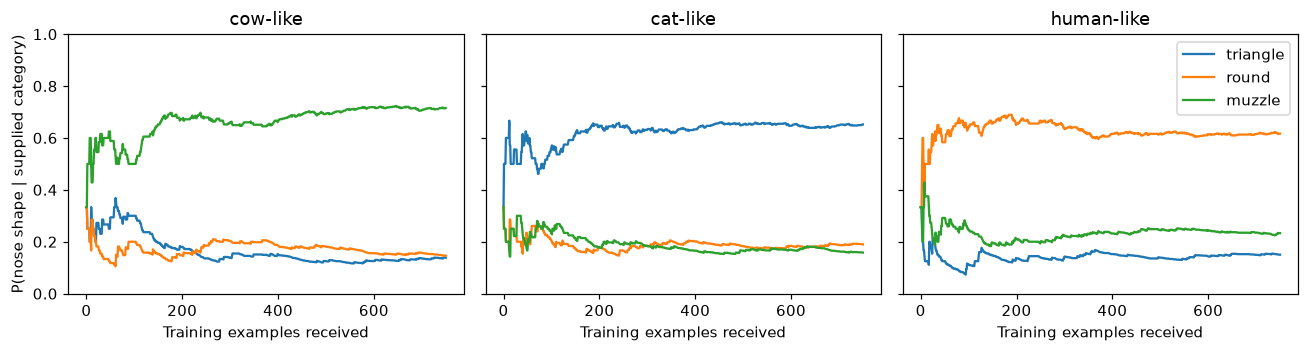

In [4]:
learner = SupervisedHebbianPrior(CARDINALITIES, len(CLASS_NAMES), SMOOTHING, LEARNING_RATE)
initial_logprior = learner.log_prior(library.states)
nose_history = [learner.feature_probabilities[3].copy()]
for state, category in zip(states_stream, labels_stream):
    learner.update(state, int(category))
    nose_history.append(learner.feature_probabilities[3].copy())
nose_history = np.stack(nose_history)
learned_logprior = learner.log_prior(library.states)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for c, ax in enumerate(axes):
    for value, name in enumerate(FACTOR_VALUES[3]):
        ax.plot(nose_history[:, c, value], label=name)
    ax.set(title=CLASS_NAMES[c], xlabel="Training examples received", ylim=(0, 1))
axes[0].set_ylabel("P(nose shape | supplied category)")
axes[-1].legend()
fig.tight_layout(); fig.savefig(OUT / "learning_curves.png", dpi=160); plt.show()
print("Examples seen:", learner.n_samples_seen)
print("Final nose probabilities, rows = cow-like / cat-like / human-like:")
print(np.round(learner.feature_probabilities[3], 3))

## Comparison with the original batch fitter

At rate 1, the original fitter and the streamed learner should agree to floating-point precision. For a different positive rate, the equivalent batch pseudocount is `SMOOTHING / LEARNING_RATE`. Both statements apply to the category prior. Other prior families keep their original smoothing.

The adapter `fit_priors(..., category_learning="hebbian")` integrates the online rule into the original notebook. `category_learning="counts"` selects the original fitter.

In [5]:
batch = fit_priors(library, training_ids, training_labels, smoothing=SMOOTHING,
                   category_learning="counts")
online = fit_priors(library, training_ids, training_labels, smoothing=SMOOTHING,
                    category_learning="hebbian", hebbian_learning_rate=LEARNING_RATE)
equivalent_batch = fit_priors(library, training_ids, training_labels,
                              smoothing=SMOOTHING / LEARNING_RATE, category_learning="counts")
np.testing.assert_allclose(learned_logprior, online.logpriors["category"], atol=1e-12)
np.testing.assert_allclose(learned_logprior, equivalent_batch.logpriors["category"], atol=1e-12)
prior_difference = float(np.max(np.abs(np.exp(learned_logprior) - np.exp(batch.logpriors["category"]))))
print("Maximum probability difference from same-smoothing batch:", prior_difference)
if LEARNING_RATE == 1:
    np.testing.assert_allclose(learned_logprior, batch.logpriors["category"], atol=1e-12)

Maximum probability difference from same-smoothing batch: 0.0


## Completion before and after training

The hidden drawing below is a held-out combination. The observed top strip and mask are the only image input to the evidence scorer. The category prior mixes all training categories. A label is used to choose the demonstration stimulus, then withheld during inference.

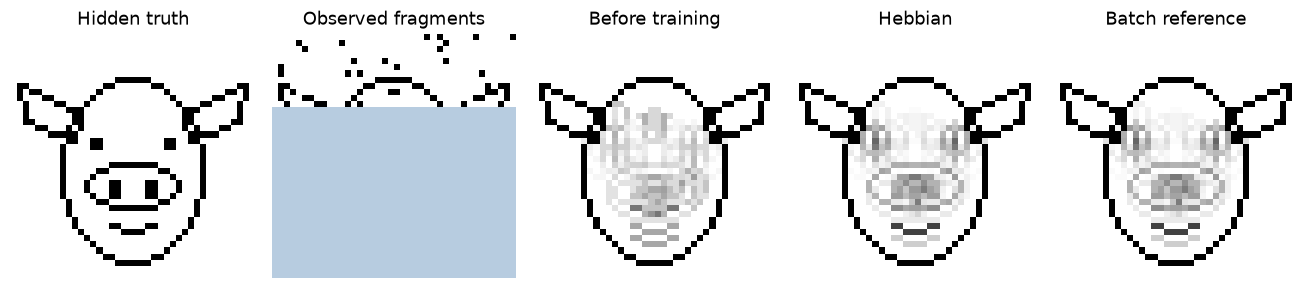

In [6]:
demo_id = int(library.test_ids[np.argmax(library.teacher_logp[0, library.test_ids])])
truth = library.images[demo_id]
mask = np.broadcast_to(np.arange(IMAGE_SIZE)[:, None] < round(.30*IMAGE_SIZE), truth.shape).copy()
observed = observe(truth, mask, FLIP_PROBABILITY, np.random.default_rng(37))
encoder = PixelVSA(IMAGE_SIZE, VSA_DIM, SEED+10)
loglik = encoder.evidence_scores(library.images, observed, mask, FLIP_PROBABILITY, "vsa")
conditions = [("Before training", initial_logprior), ("Hebbian", learned_logprior),
              ("Batch reference", batch.logpriors["category"])]
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
show_completion(axes[0], truth, "Hidden truth")
show_observation(axes[1], observed, mask)
for ax, (name, logprior) in zip(axes[2:], conditions):
    show_completion(ax, prediction(posterior(loglik, logprior), library.images), name)
fig.tight_layout(); fig.savefig(OUT / "completion_comparison.png", dpi=160); plt.show()

## Paired held-out checks

The same held-out observations are scored with streamed and batch priors. We check full-candidate posterior probabilities with both image-evidence backends and compare dense iterative inference on the demonstration. Ground truth is used to score completed images. No completion trial changes the learned weights.

In [7]:
trials = sample_trials(library, TRIALS_PER_VISIBILITY, VISIBILITIES,
                       seed=SEED+100, flip_probability=FLIP_PROBABILITY)
metric_rows = []
posterior_difference = 0.
for trial in trials:
    for backend in ("pixels", "vsa"):
        ll = encoder.evidence_scores(library.images, trial["observed"], trial["mask"],
                                     FLIP_PROBABILITY, backend)
        q_online = posterior(ll, learned_logprior)
        q_batch = posterior(ll, batch.logpriors["category"])
        posterior_difference = max(posterior_difference, float(np.max(np.abs(q_online-q_batch))))
        for name, q in (("hebbian", q_online), ("counts", q_batch)):
            metrics = completion_metrics(prediction(q, library.images), trial["truth"],
                                          trial["observed"], trial["mask"])
            metric_rows.append(dict(backend=backend, learner=name, **metrics))
mf_online = mean_field(loglik, learned_logprior, library.states, CARDINALITIES, sweeps=25, seed=SEED)
mf_batch = mean_field(loglik, batch.logpriors["category"], library.states, CARDINALITIES, sweeps=25, seed=SEED)
iterative_difference = float(np.max(np.abs(mf_online["joint"]-mf_batch["joint"])))
if LEARNING_RATE == 1:
    assert posterior_difference < 1e-10
    assert iterative_difference < 1e-10
print("Maximum full-candidate probability difference:", posterior_difference)
print("Maximum iterative joint probability difference:", iterative_difference)
for backend in ("pixels", "vsa"):
    for name in ("counts", "hebbian"):
        subset = [r for r in metric_rows if r["backend"] == backend and r["learner"] == name]
        print(backend, name, {m:round(float(np.mean([r[m] for r in subset])), 5)
              for m in ("hidden_brier", "hidden_recall", "hidden_false_positive")})
summary = dict(training_examples=learner.n_samples_seen, held_out_trials=len(trials),
               learning_rate=LEARNING_RATE, smoothing=SMOOTHING,
               max_prior_probability_difference=prior_difference,
               max_posterior_probability_difference=posterior_difference,
               max_iterative_probability_difference=iterative_difference)
(OUT / "comparison_summary.json").write_text(json.dumps(summary, indent=2))
np.savez(OUT / "learned_weights.npz", category_weights=learner.category_weights,
         **{f"feature_{j}": w for j, w in enumerate(learner.feature_weights)})
print("Saved summary and learned weights to", OUT)

Maximum full-candidate probability difference: 0.0
Maximum iterative joint probability difference: 0.0
pixels counts {'hidden_brier': 0.01195, 'hidden_recall': 0.87817, 'hidden_false_positive': 0.00698}
pixels hebbian {'hidden_brier': 0.01195, 'hidden_recall': 0.87817, 'hidden_false_positive': 0.00698}
vsa counts {'hidden_brier': 0.01231, 'hidden_recall': 0.88064, 'hidden_false_positive': 0.00704}
vsa hebbian {'hidden_brier': 0.01231, 'hidden_recall': 0.88064, 'hidden_false_positive': 0.00704}
Saved summary and learned weights to C:\NEU_172L\vsa_gestalt_closure_hebbian\outputs\hebbian


## What this addition implements

The learner updates connections from co-active supplied category and feature units. It reads normalized weights as feature probabilities and mixes the learned category distributions using their learned frequencies. At the default settings, the completed drawings match the batch-count reference.

This version retains explicit labels and feature dictionaries. The update is a rate-based, supervised Hebbian rule with probabilistic normalization. Learning happens over a stream, while inference uses the same VSA representation and candidate model as before. Future experiments can add decay or inferred category activity and use the batch-equivalent version as their reference.